## Бинарные пороги (бинаризация изображений)

1. **Построить гистограмму** яркости для каждого изображения.
2. **Выбрать значение бинарного порога** и выполнить бинаризацию.
3. **Применить адаптивный порог**, если использование единичного (глобального) порога даёт неудовлетворительный результат.
4. **Применить порог в разных каналах цветности**, если адаптивный порог не справляется с задачей, и **качественно сравнить** полученные результаты.
5. **Сравнить результаты количественно**:
   * Сгенерировать тестовое изображение с одиночным белым объектом на чёрном фоне.
   * Добавить шум яркости.
   * Выполнить бинаризацию.
   * Сравнить площадь исходного и полученного после бинаризации объектов.
   * Повторить эксперимент для разных уровней шума.

In [13]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Путь к папке
base_path = Path(r"C:\Users\maybn\Documents\GitHub\Computer-graphics\Конспекты\lab04_binary_thresholding\Картинки с выставки")
# Список путей к файлам
image_paths = sorted(list(base_path.glob("*.jpg")) + list(base_path.glob("*.png")))

# Списки для хранения
images_gray = []
images_color = []
names = []

# Цикл загрузки
for path in image_paths:
    # Чтение (обход кириллицы)
    img_gray = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_GRAYSCALE)
    img_color = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)
    
    # Добавление в списки
    images_gray.append(img_gray)
    images_color.append(img_color)
    names.append(path.name)

print(f"Загружено: {len(images_gray)} шт.")

Загружено: 4 шт.


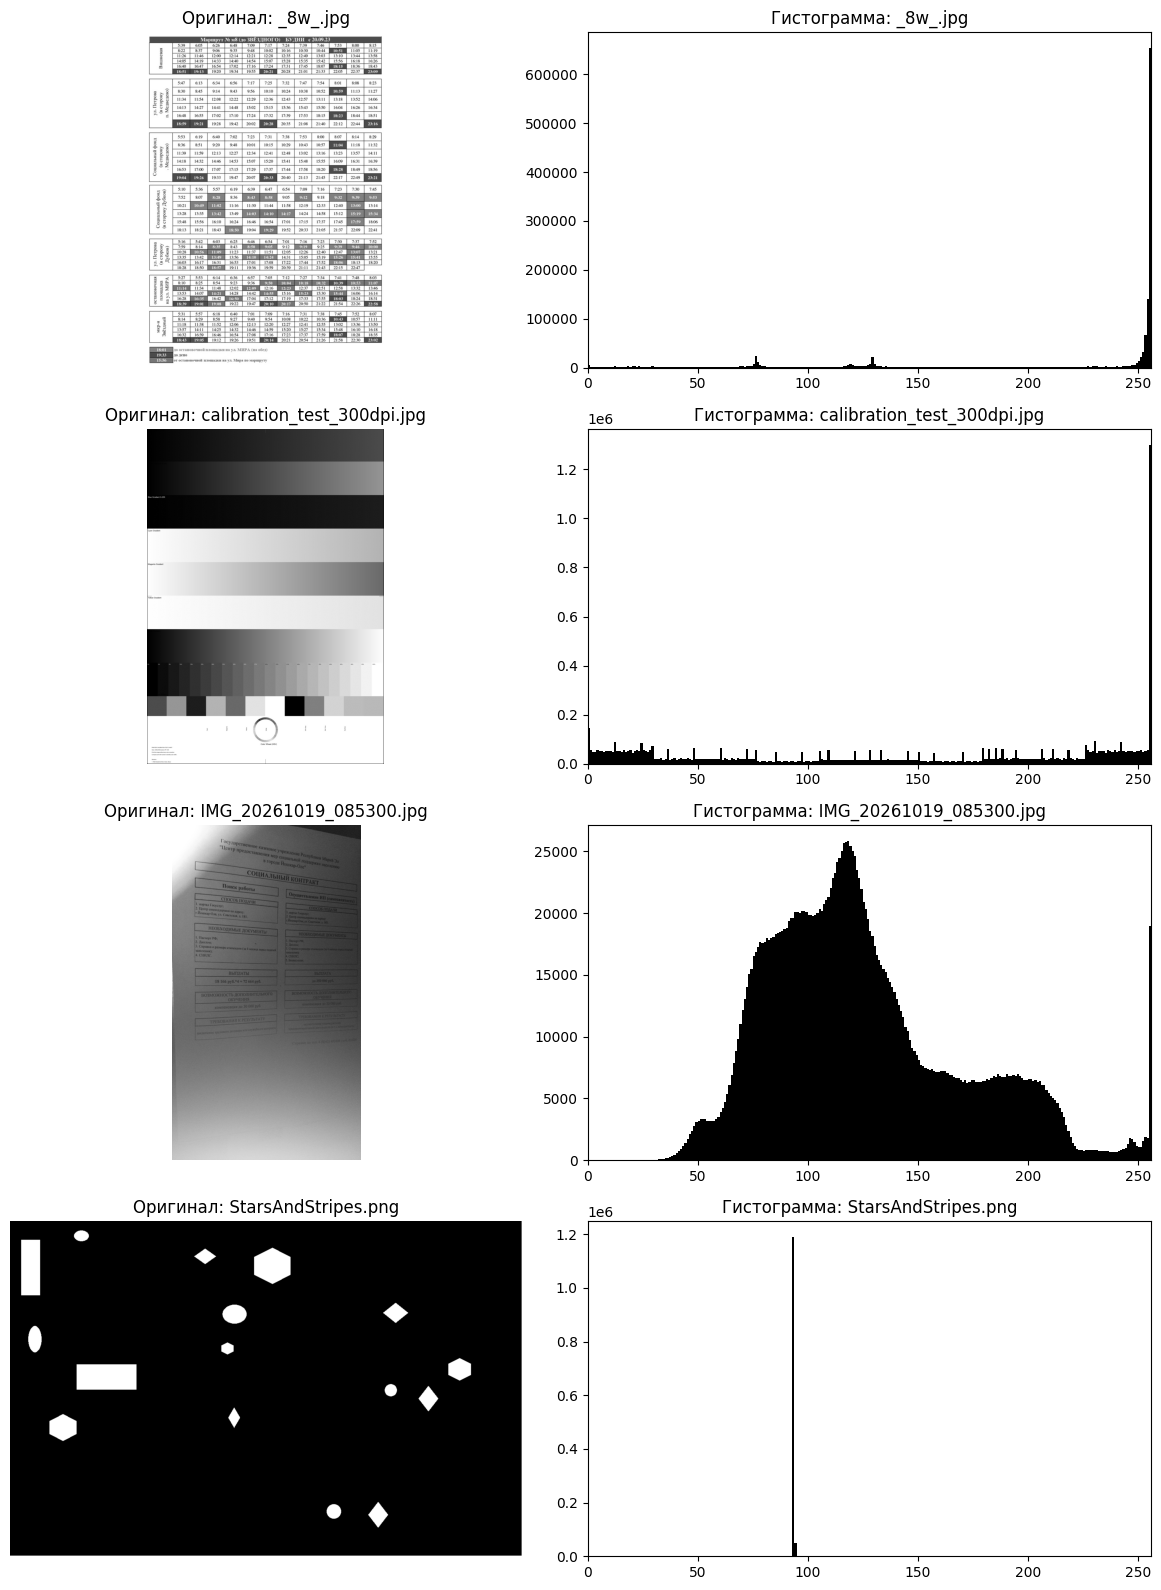

In [14]:
# Создаем сетку графиков (len(images_gray) строк, 2 колонки)
fig, axes = plt.subplots(len(images_gray), 2, figsize=(12, 4 * len(images_gray)))

# Проходимся по каждому изображению
for i in range(len(images_gray)):
    img = images_gray[i]
    name = names[i]
    
    # Левая колонка: оригинал в градациях серого
    axes[i, 0].imshow(img, cmap='gray')
    axes[i, 0].set_title(f"Оригинал: {name}")
    axes[i, 0].axis('off')
    
    # Правая колонка: гистограмма яркости
    # ravel() превращает 2D-массив в 1D для построения гистограммы
    axes[i, 1].hist(img.ravel(), bins=256, range=[0, 256], color='black')
    axes[i, 1].set_title(f"Гистограмма: {name}")
    axes[i, 1].set_xlim([0, 256])

plt.tight_layout() # Убираем наложение элементов
plt.show()

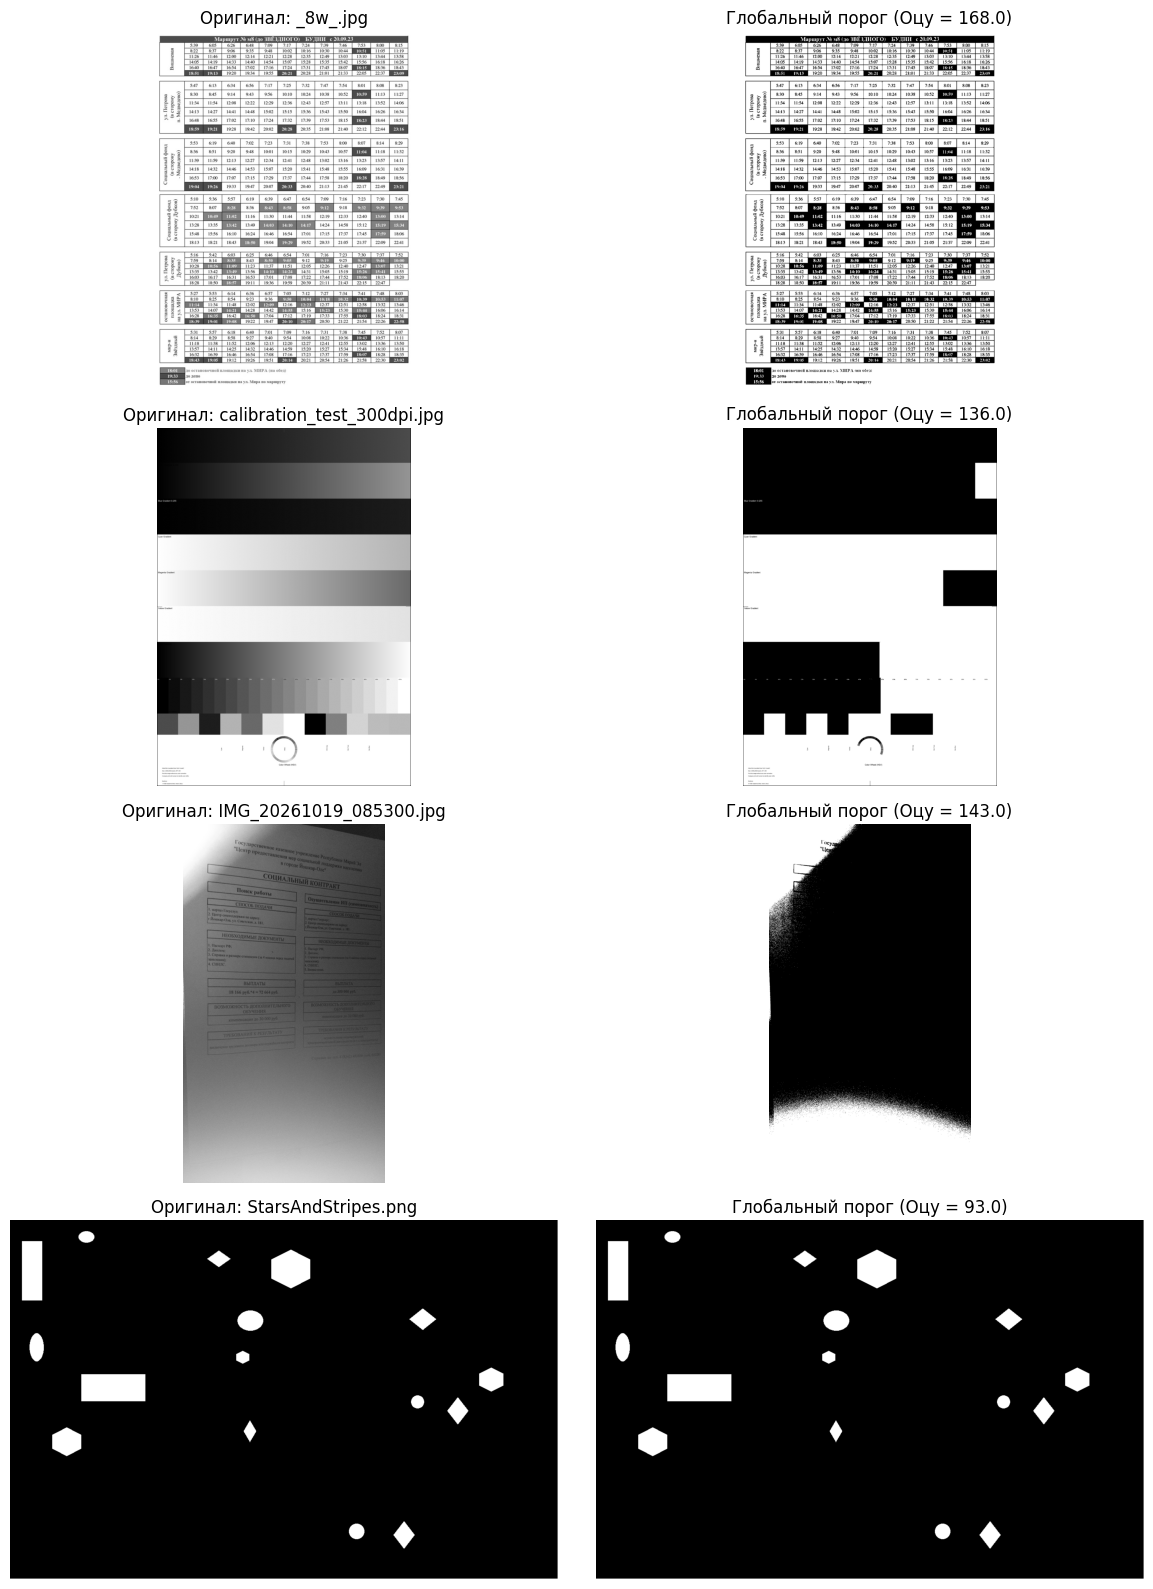

In [15]:
fig, axes = plt.subplots(len(images_gray), 2, figsize=(12, 4 * len(images_gray)))

for i in range(len(images_gray)):
    img = images_gray[i]
    
    # Метод Оцу: автоматический подбор единого порога
    ret, th_global = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    
    axes[i, 0].imshow(img, cmap='gray')
    axes[i, 0].set_title(f"Оригинал: {names[i]}")
    axes[i, 0].axis('off')
    
    # Отображение результата бинаризации
    axes[i, 1].imshow(th_global, cmap='gray')
    axes[i, 1].set_title(f"Глобальный порог (Оцу = {ret:.1f})")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

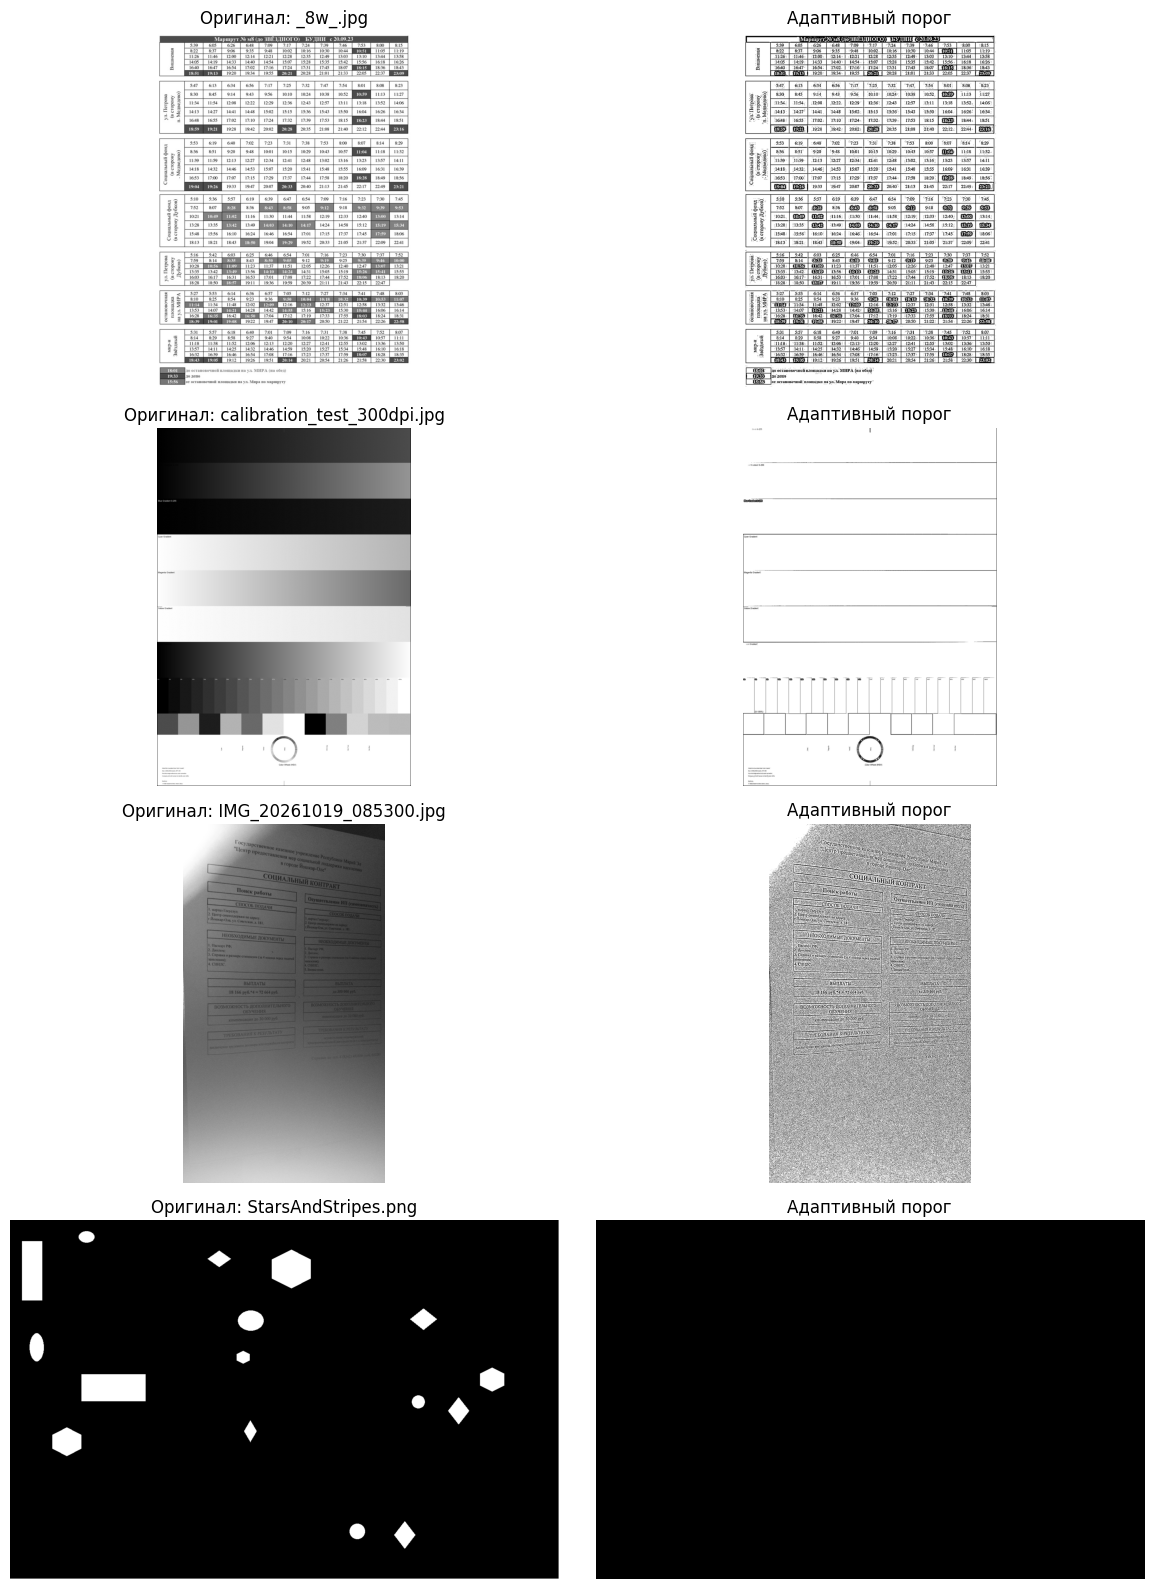

In [16]:
fig, axes = plt.subplots(len(images_gray), 2, figsize=(12, 4 * len(images_gray)))

for i in range(len(images_gray)):
    img = images_gray[i]
    
    # Адаптивный порог: вычисляется локально в окне 11x11 (константа 2)
    # Решает проблему теней и градиентов освещения
    th_adaptive = cv2.adaptiveThreshold(
        img, 255, 
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
        cv2.THRESH_BINARY, 
        11, 2
    )
    
    axes[i, 0].imshow(img, cmap='gray')
    axes[i, 0].set_title(f"Оригинал: {names[i]}")
    axes[i, 0].axis('off')
    
    axes[i, 1].imshow(th_adaptive, cmap='gray')
    axes[i, 1].set_title("Адаптивный порог")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

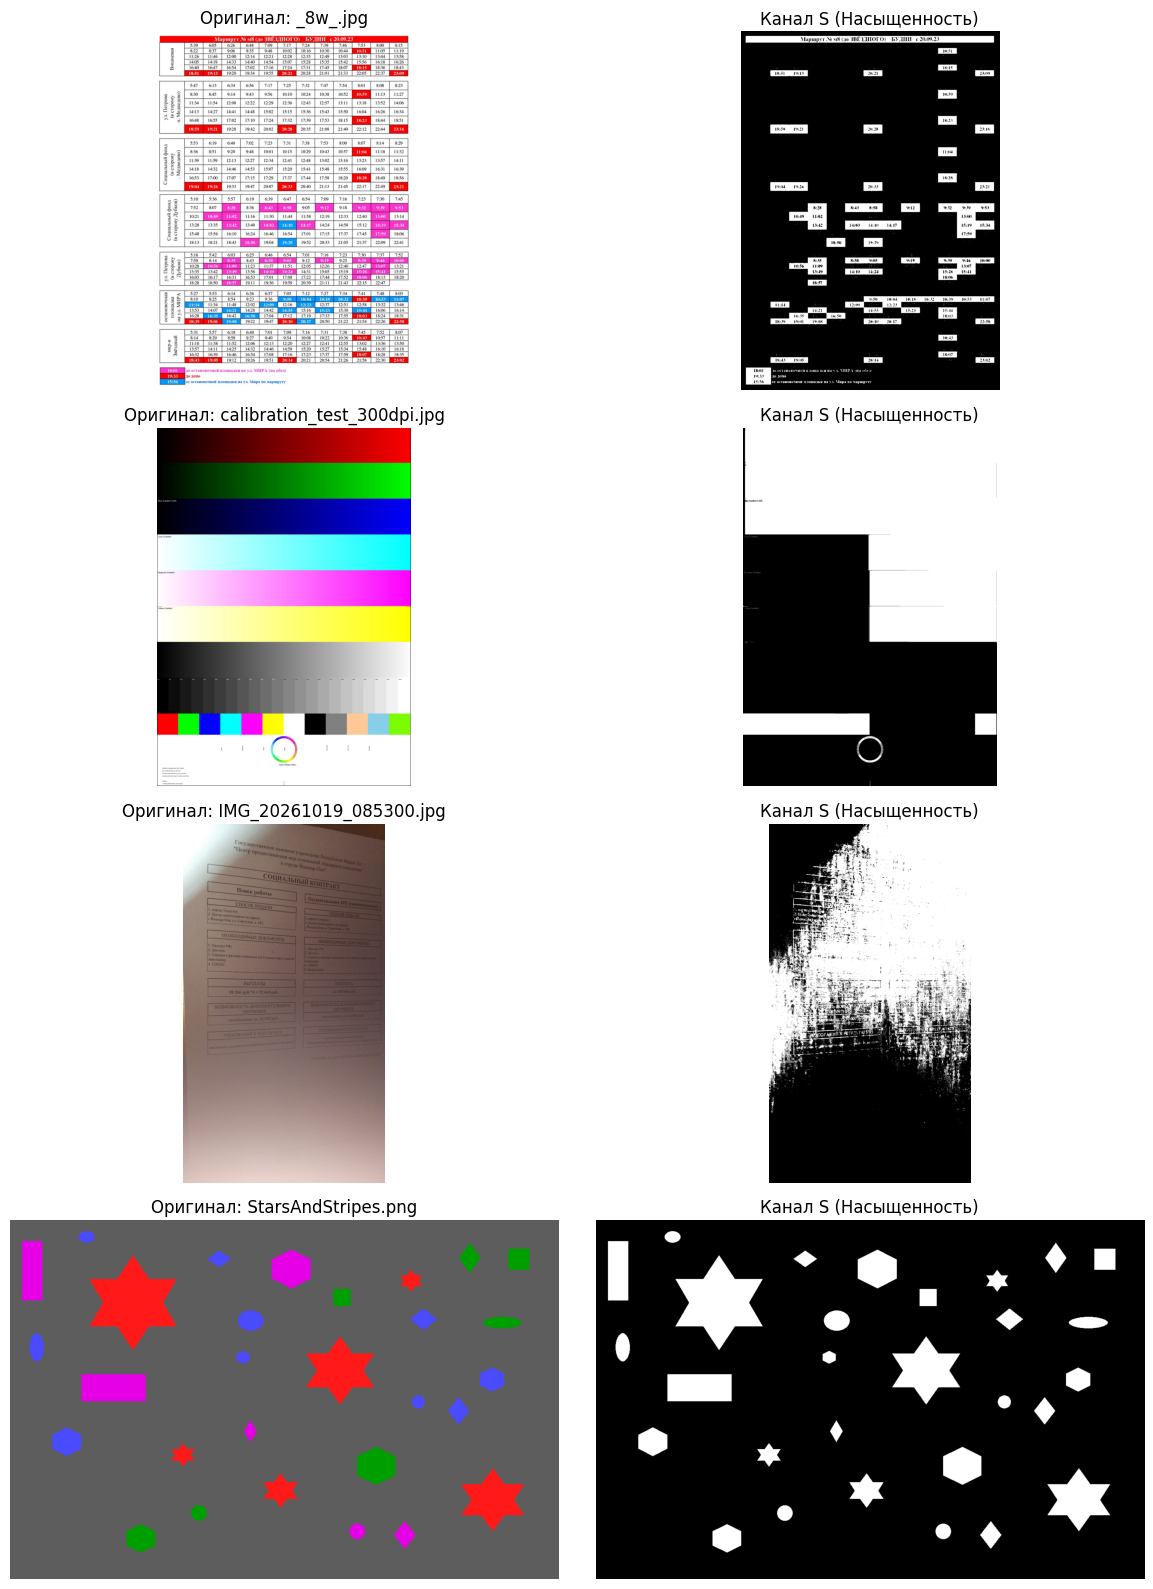

In [17]:
fig, axes = plt.subplots(len(images_color), 2, figsize=(12, 4 * len(images_color)))

for i in range(len(images_color)):
    img_bgr = images_color[i]
    
    # Перевод из BGR в HSV
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    # Разделение на каналы: H (тон), S (насыщенность), V (яркость)
    h, s, v = cv2.split(hsv)
    
    # Бинаризация по каналу S (насыщенность) — лучше выделяет цветные объекты
    _, th_s = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    # Перевод обратно в RGB для корректного отображения в matplotlib
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    axes[i, 0].imshow(img_rgb)
    axes[i, 0].set_title(f"Оригинал: {names[i]}")
    axes[i, 0].axis('off')
    
    axes[i, 1].imshow(th_s, cmap='gray')
    axes[i, 1].set_title("Канал S (Насыщенность)")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

Идеальная площадь объекта: 7845 пикселей

Шум (sigma)     | Площадь    | Ошибка (%)
---------------------------------------------
5               | 7845       | 0.00%
15              | 7845       | 0.00%
30              | 7845       | 0.00%
50              | 8342       | 6.34%
80              | 16578      | 111.32%
120             | 23807      | 203.47%


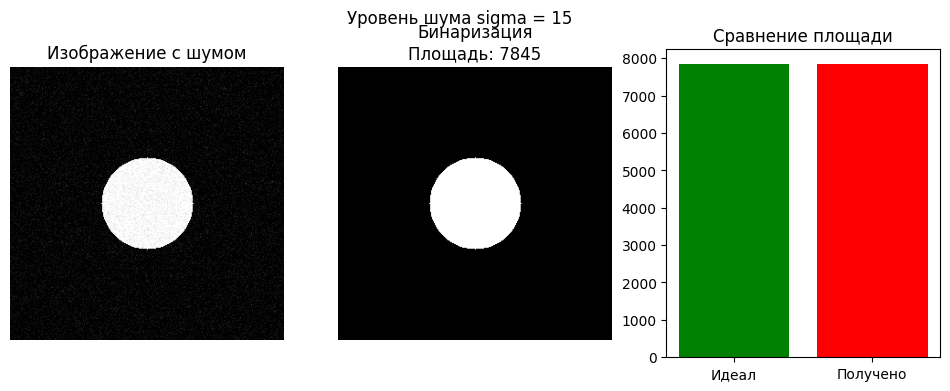

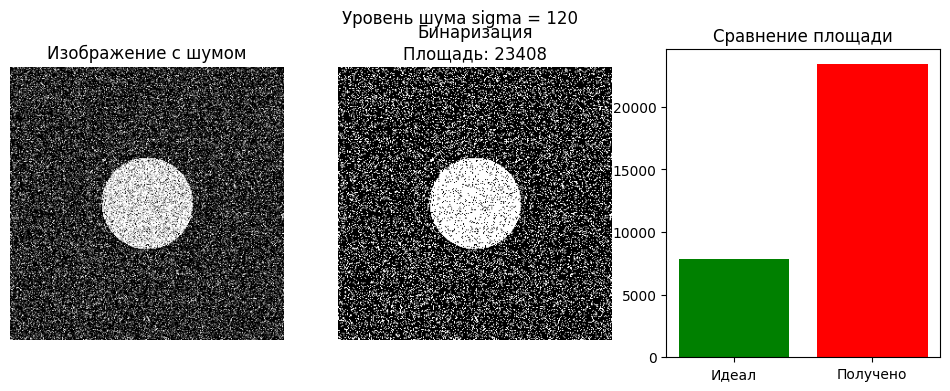

In [18]:
# 1. Создаем идеальное изображение: белый круг на черном фоне
canvas = np.zeros((300, 300), dtype=np.uint8)
cv2.circle(canvas, (150, 150), 50, 255, -1)
# Считаем эталонную площадь (количество белых пикселей)
ideal_area = np.sum(canvas == 255)
print(f"Идеальная площадь объекта: {ideal_area} пикселей\n")

# 2. Функция добавления гауссова шума
def add_noise(image, sigma):
    noise = np.random.normal(0, sigma, image.shape)
    noisy = image + noise
    return np.clip(noisy, 0, 255).astype(np.uint8) # Обрезаем значения в диапазон [0, 255]

sigmas = [5, 15, 30, 50, 80, 120] # Разные уровни шума
results = []

print(f"{'Шум (sigma)':<15} | {'Площадь':<10} | {'Ошибка (%)':<10}")
print("-" * 45)

# 3. Цикл по уровням шума
for sigma in sigmas:
    noisy_img = add_noise(canvas, sigma)
    # Бинаризация зашумленного изображения
    _, binary = cv2.threshold(noisy_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    # Считаем площадь полученного объекта
    measured_area = np.sum(binary == 255)
    # Вычисляем относительную ошибку в процентах
    error = abs(measured_area - ideal_area) / ideal_area * 100
    results.append((sigma, measured_area, error))
    print(f"{sigma:<15} | {measured_area:<10} | {error:.2f}%")

# 4. Визуализация для двух уровней шума (малый и большой)
for sigma in [15, 120]:
    noisy_img = add_noise(canvas, sigma)
    _, binary = cv2.threshold(noisy_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    
    plt.figure(figsize=(12, 4))
    plt.suptitle(f"Уровень шума sigma = {sigma}")
    
    plt.subplot(1, 3, 1)
    plt.imshow(noisy_img, cmap='gray')
    plt.title("Изображение с шумом")
    plt.axis('off')
    
    plt.subplot(1, 3, 2)
    plt.imshow(binary, cmap='gray')
    plt.title(f"Бинаризация\nПлощадь: {np.sum(binary == 255)}")
    plt.axis('off')
    
    plt.subplot(1, 3, 3)
    # Столбчатая диаграмма сравнения площадей
    plt.bar(['Идеал', 'Получено'], [ideal_area, np.sum(binary == 255)], color=['green', 'red'])
    plt.title("Сравнение площади")
    plt.show()